# Session Title: Artificial Netural Networks for classification

**Instructor:** Zahra Sadeghi

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

from sklearn.datasets import make_moons
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import accuracy_score

In [ ]:
X, y = make_moons(
    n_samples=1000,
    noise=0.2,
    random_state=42
)

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    stratify=y,
    random_state=42
)

scaler = StandardScaler()

X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

**Full-batch Gradient Descent**

In [ ]:
batch_size = len(X_train)

One subtle point: in scikit-learn's implementation, the output activation is handled internally according to the classification task.
activation="relu" only specifies the hidden layers.

In [ ]:
mlp_full = MLPClassifier(
    hidden_layer_sizes=(20, 20),
    activation="relu",
    solver="sgd",
    learning_rate_init=0.01,
    batch_size=len(X_train),   # Full batch
    max_iter=100,
    random_state=42
)

mlp_full.fit(X_train, y_train)

/usr/local/lib/python3.13/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:691: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (100) reached and the optimization hasn't converged yet.
  warnings.warn(


MLPClassifier(batch_size=800, hidden_layer_sizes=(20, 20),
              learning_rate_init=0.01, max_iter=100, random_state=42,
              solver='sgd')

**Stochastic Gradient Descent**

In [ ]:
batch_size = 1

In [ ]:
mlp_sgd = MLPClassifier(
    hidden_layer_sizes=(20, 20),
    activation="relu",
    solver="sgd",
    learning_rate_init=0.01,
    batch_size=1,              # stochastic GD: batch_size=1
    max_iter=100,              # max_iter is the maximum number of epochs
    random_state=42
)

mlp_sgd.fit(X_train, y_train)

MLPClassifier(batch_size=1, hidden_layer_sizes=(20, 20),
              learning_rate_init=0.01, max_iter=100, random_state=42,
              solver='sgd')

**Mini-batch Gradient Descent**

In [ ]:
batch_size = 32

In [ ]:
mlp_mini = MLPClassifier(
    hidden_layer_sizes=(20, 20),
    activation="relu",
    solver="sgd",
    learning_rate_init=0.01,
    batch_size=32,             # Mini-batch
    max_iter=100,
    random_state=42
)

mlp_mini.fit(X_train, y_train)

MLPClassifier(batch_size=32, hidden_layer_sizes=(20, 20),
              learning_rate_init=0.01, max_iter=100, random_state=42,
              solver='sgd')

Compare the Loss curves

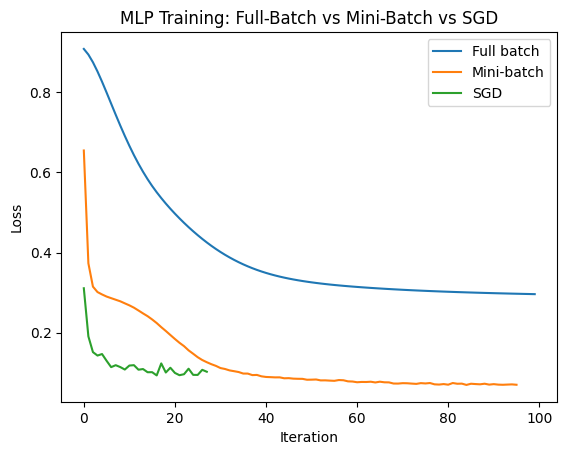

In [ ]:
plt.plot(mlp_full.loss_curve_, label="Full batch")
plt.plot(mlp_mini.loss_curve_, label="Mini-batch")
plt.plot(mlp_sgd.loss_curve_, label="SGD")

plt.xlabel("Iteration")
plt.ylabel("Loss")
plt.legend()
plt.title("MLP Training: Full-Batch vs Mini-Batch vs SGD")
plt.show()